# Clasificación calibrada de señales de tránsito de Kepler
### Red multirrama con un codificador por tránsito con atención · Curso de Deep Learning

**Juan Sebastian Higuita Riascos** · Especialización en Inteligencia Artificial, Universidad Nacional de Colombia

Este notebook **no entrena nada**: lee las predicciones y tablas que dejaron los scripts del repositorio (`resultados/dl/`) y las dibuja. Cada cifra que aparece aquí sale de esos archivos.

| Sección | Pregunta | Qué puedes mover |
|---|---|---|
| 1 | ¿Qué datos hay y cómo se ven? | La señal que se dibuja |
| 2 | ¿Cuál es el listón que hay que superar? | — |
| 3 | **P1.** ¿Qué arquitectura lee mejor la señal de tránsito? | La métrica · la semilla |
| 4 | ¿A qué tránsitos presta atención el modelo? | — |
| 5 | **P2.** ¿Cuánto mejora la decisión al fusionar las cuatro ramas? | La métrica |
| 6 | **P3.** ¿Se puede confiar en las probabilidades? | Los intervalos · la temperatura · la cobertura |
| 7 | Explorador de señales | Grupo · señal · tasa base |
| 8 | Veredicto de las hipótesis y limitaciones | — |

**Cómo usarlo.** Ejecuta todas las celdas (*Run → Run All Cells*). Debajo de varias figuras aparecen **controles**: al moverlos, la figura se vuelve a dibujar. Si lo lees sin ejecutar, verás cada figura con sus valores iniciales.

**Cómo leer el código.** Cada celda hace una sola cosa y llama a una función de `src/informe/`. Para ver cómo está hecha una figura, escribe por ejemplo `secciones.calibracion??` en una celda nueva.

> **Qué es de este curso y qué no.** Las ramas 1 (vistas), 2 (tránsitos) y 4 (escalares), la fusión y la calibración son de este curso. La **rama 3 (imagen)** es el codificador **v0 de la demo**, código anterior a los cursos, usado congelado: no es un aporte de este trabajo.

In [1]:
import sys
import warnings
from pathlib import Path

from IPython.display import display

warnings.filterwarnings("ignore")

# 1. Ubicar la carpeta del repositorio y hacer visible su código (src/)
RAIZ = next(
    carpeta
    for carpeta in [Path.cwd(), *Path.cwd().parents]
    if (carpeta / "config" / "protocolo.json").is_file()
)
sys.path.insert(0, str(RAIZ / "src"))

# 2. Módulos del informe: lectura de resultados, figuras y controles
from informe import datos, graficos, secciones
from informe.interactivo import Deslizador, Explorador, Lista, controles

# 3. Cargar el dataset y la tabla de ejemplos una sola vez
graficos.aplicar_estilo()
res = datos.cargar(RAIZ)

print(f"{len(res.ids)} ejemplos de {res.tabla.kepid.nunique()} estrellas, listos en `res`.")

490 ejemplos de 245 estrellas, listos en `res`.


## 1 · Los datos

Kepler midió el brillo de cada estrella cada 30 minutos durante 4 años. Un planeta que pasa por delante produce una **caída periódica**. Pero hay impostores: estrellas dobles que se eclipsan, estrellas vecinas y fallas del instrumento.

Cada señal (KOI, *Kepler Object of Interest*) da **dos ejemplos**: el tránsito real (*planeta* o *falso positivo*, según el catálogo DR25 de NASA) y la misma estrella en una época desplazada un cuarto de órbita, con la señal real oculta (*sin señal*).

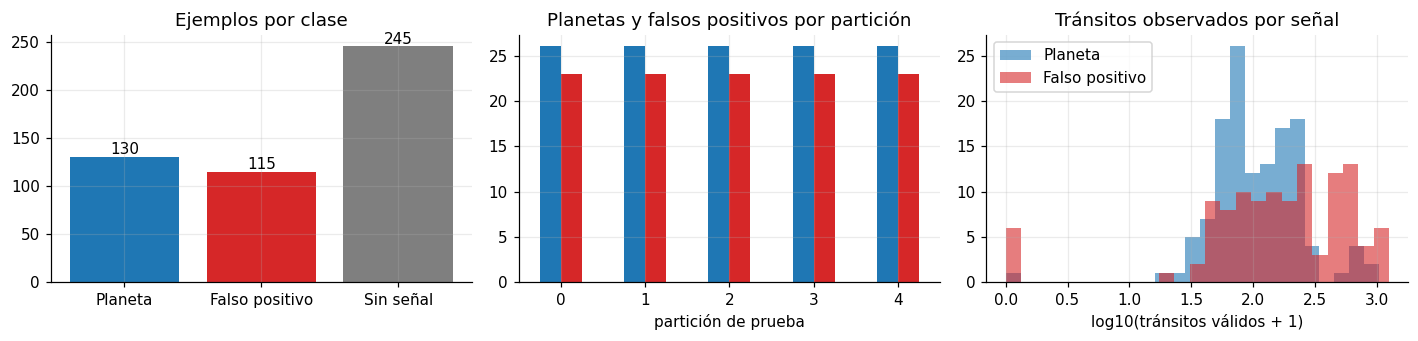

490 ejemplos de 245 estrellas · disponibles para la rama 1 (vistas): 467 · para la rama 2 (tránsitos): 471


In [2]:
# Cuántos ejemplos hay, cómo se reparten en las 5 particiones y cuántos tránsitos tiene cada señal
secciones.resumen_de_datos(res)

### Tres formas de mirar la misma curva de luz

- **Vista plegada (rama 1):** todos los tránsitos apilados y promediados. Limpia el ruido, pero borra las diferencias entre un tránsito y otro.
- **Tránsitos uno por uno (rama 2):** hasta 32 ventanas individuales. Permite ver si un tránsito no se parece a los demás.
- **Escalares (rama 4):** periodo, duración, profundidad, relación señal/ruido y desplazamiento de centroide.

Todo está en **unidades de profundidad**: un tránsito real vale cerca de −1.

**Prueba esto.** Compara `K00022.01` (planeta confirmado) con `K03615.01` (estrella doble). En la estrella doble los eclipses **impares son más profundos que los pares**: en la vista plegada "todos" esa diferencia se promedia y desaparece; en los tránsitos uno por uno se ve fila a fila.

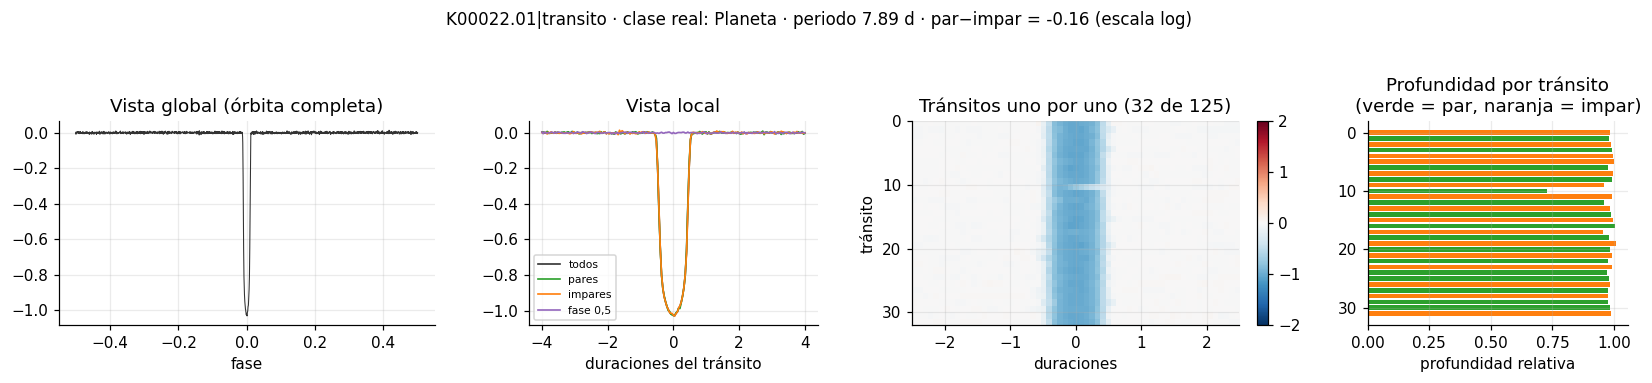

(Vista fija con Señal: K00022.01|transito. Ejecuta el notebook para usar los controles.)


In [3]:
# Señales reales (no las copias "sin señal"), con dos casos ilustrativos al principio de la lista
senales = sorted(res.ids[res.y < 2])
ilustrativos = ["K00022.01|transito", "K03615.01|transito"]
opciones = ilustrativos + [s for s in senales if s not in ilustrativos]

controles(
    lambda id_ejemplo: graficos.ver_ejemplo(res, id_ejemplo),
    id_ejemplo=Lista("Señal:", opciones),
)

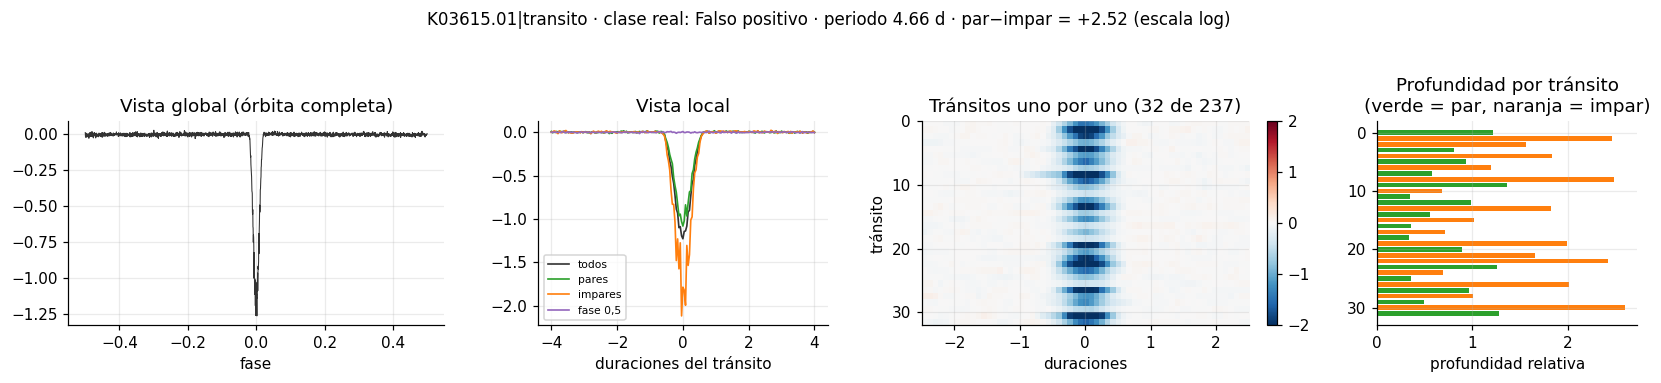

In [4]:
# El segundo caso ilustrativo, fijo, para comparar con el de arriba
graficos.ver_ejemplo(res, "K03615.01|transito")

## 2 · El listón

Antes de entrenar redes se midió qué logra un modelo **tabular** (*gradient boosting*, árboles de decisión encadenados) sin columnas con fuga, y se volvió a medir la **demo** sobre esta misma base y con las mismas particiones.

- **S3-B:** periodo, duración, profundidad, SNR, número de tránsitos y magnitud.
- **S3-C:** S3-B más el desplazamiento de centroide.
- `koi_score` es la decisión del Robovetter de NASA: **nunca es una entrada**, solo un comparador externo.

**Cómo leer la figura.** Cada punto es un **AUC planeta vs falso positivo** (0,5 = azar, 1 = perfecto). La barra es su **intervalo de confianza del 95 %**, calculado remuestreando estrellas (*bootstrap*).

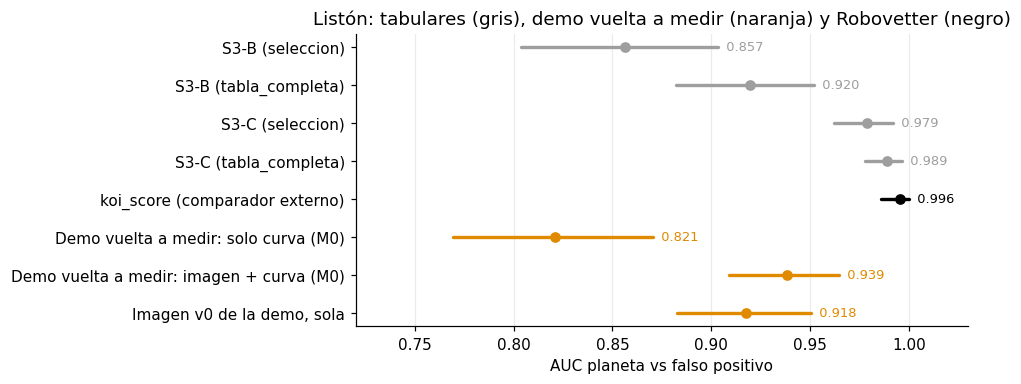

,modelo,auc,ic_inf,ic_sup,n
0,S3-B (seleccion),0.8565,0.8039,0.9037,245
1,S3-B (tabla_completa),0.9199,0.8823,0.9518,245
2,S3-C (seleccion),0.9788,0.9623,0.9921,245
3,S3-C (tabla_completa),0.9889,0.9781,0.9964,245
4,"koi_score (comparador externo, contiene la dec...",0.9956,0.9861,1.0000,245
5,Demo vuelta a medir: solo curva (M0),0.8212,0.7694,0.8707,222
6,Demo vuelta a medir: imagen + curva (M0),0.9385,0.9089,0.9646,222
7,"Imagen v0 de la demo, sola",0.9178,0.8826,0.9503,222


In [5]:
tabla_liston = secciones.liston(res)
display(tabla_liston)

**Lectura.** Con el centroide, un modelo tabular ya llega a **0,98–0,99**. Hay dos advertencias que el informe declara:

1. En periodo corto la revisión de Kepler ya funciona bien; no hay mucho margen por encima de ese listón.
2. Parte de las etiquetas de falso positivo se asignaron *usando* el centroide, así que S3-C mide en parte la regla que puso la etiqueta (circularidad parcial).

## 3 · P1 — ¿Qué arquitectura lee mejor la señal de tránsito?

Diseño controlado: las tres variantes de la rama 2 usan **el mismo codificador por tránsito** (una CNN 1D con pesos compartidos) y **las mismas ventanas**. Solo cambia **cómo se combinan los tránsitos**:

| Variante | Cómo combina | Supuesto que mete (sesgo inductivo) |
|---|---|---|
| Promedio | Media de los tránsitos | Todos pesan igual; el orden no importa. Equivale a plegar la curva |
| GRU | Los lee en orden cronológico | El orden importa |
| Atención | Suma ponderada con pesos aprendidos | Algunos tránsitos importan más; el orden no importa |

La CNN tipo AstroNet sobre la vista plegada (rama 1) es la línea base profunda. Cada modelo se entrenó con 3 semillas × 5 particiones.

**Cómo leer la figura.** A la izquierda, cada arquitectura con su intervalo (las rayitas negras son las 3 semillas). A la derecha, la **diferencia pareada** entre dos arquitecturas: si el intervalo cruza el 0, la diferencia no se distingue del azar.

**Prueba esto.** Cambia la métrica a NLL: ¿cambia el orden de las arquitecturas?

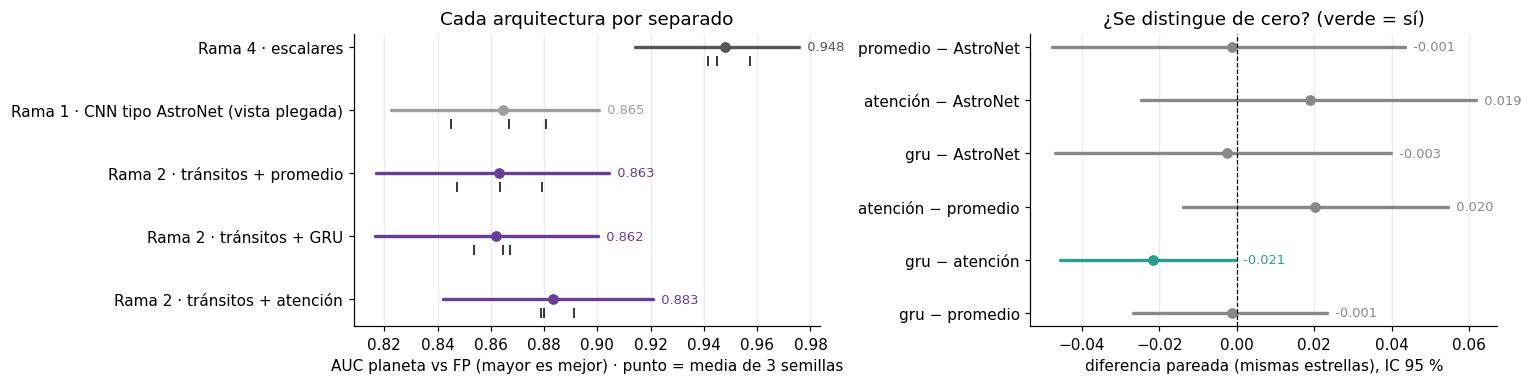

,estimacion,ic_inf,ic_sup,parametros,desviacion_semillas
modelo,,,,,
Rama 4 · escalares,0.9479,0.9142,0.9758,1059.0,0.0068
Rama 1 · CNN tipo AstroNet (vista plegada),0.8645,0.8225,0.9007,57747.0,0.0147
Rama 2 · tránsitos + promedio,0.8632,0.8170,0.9045,5027.0,0.0130
Rama 2 · tránsitos + GRU,0.8619,0.8165,0.9003,18723.0,0.0058
Rama 2 · tránsitos + atención,0.8834,0.8419,0.9208,13604.0,0.0055


(Vista fija con Métrica: auc_planeta_fp. Ejecuta el notebook para usar los controles.)


In [6]:
METRICAS = [(nombre, clave) for clave, nombre in datos.NOMBRE_DE_METRICA.items()]

controles(
    lambda metrica: secciones.arquitecturas(res, metrica),
    metrica=Lista("Métrica:", METRICAS),
)

**Lectura.**

- La **atención** tiene el AUC más alto de las ramas temporales, pero **su ventaja sobre el promedio y sobre AstroNet no se distingue de cero**: los intervalos de las diferencias incluyen el 0.
- La única diferencia distinguible es **atención > GRU**, y por poco.
- Era el resultado esperable en periodo corto: con decenas o cientos de tránsitos por estrella, promediar ya recoge casi toda la información. La hipótesis de que la atención ayuda con *pocos* tránsitos (zona habitable) **no se puede evaluar con estos datos**.

### ¿Importa el orden de los tránsitos? (prueba de permutación)

Se barajó el orden de los tránsitos de cada ejemplo de prueba, 10 veces, y se midió cuánto cambia la probabilidad.

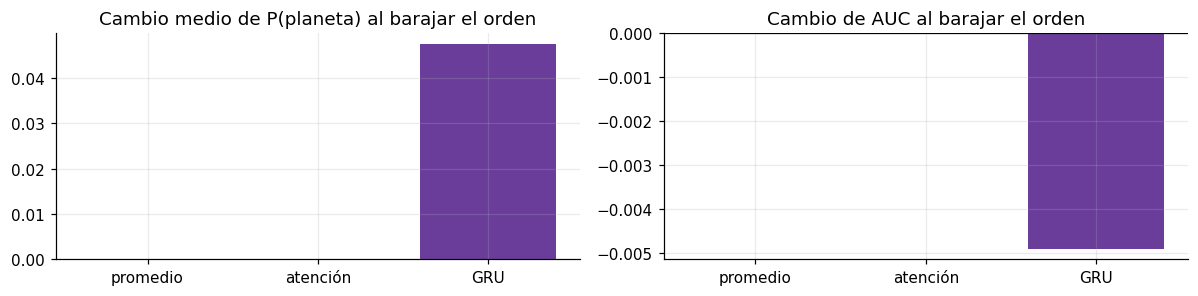

,modelo,cambio_medio_abs_de_q,cambio_de_auc
0,m2_promedio,0.00000,-0.0000
1,m2_atencion,0.00000,-0.0000
2,m2_gru,0.04757,-0.0049


In [7]:
tabla_permutacion = secciones.permutacion(res)
display(tabla_permutacion)

**Lectura.** Promedio y atención **no cambian nada** (cambio exactamente 0): por construcción ignoran el orden, y la prueba confirma que la implementación lo cumple. La GRU **sí usa el orden** (cambia la probabilidad en unos 0,05 en promedio), pero esa información extra no le dio ventaja.

### ¿Cómo entrenaron? (curvas de pérdida)

Cada línea es una de las 5 particiones. Azul: pérdida en entrenamiento. Rojo: pérdida en la **validación interna**, que decide cuándo parar. Si el rojo sube mientras el azul baja, el modelo está memorizando: por eso se detiene en la línea vertical.

**Prueba esto.** Cambia la semilla: la forma de las curvas debe parecerse.

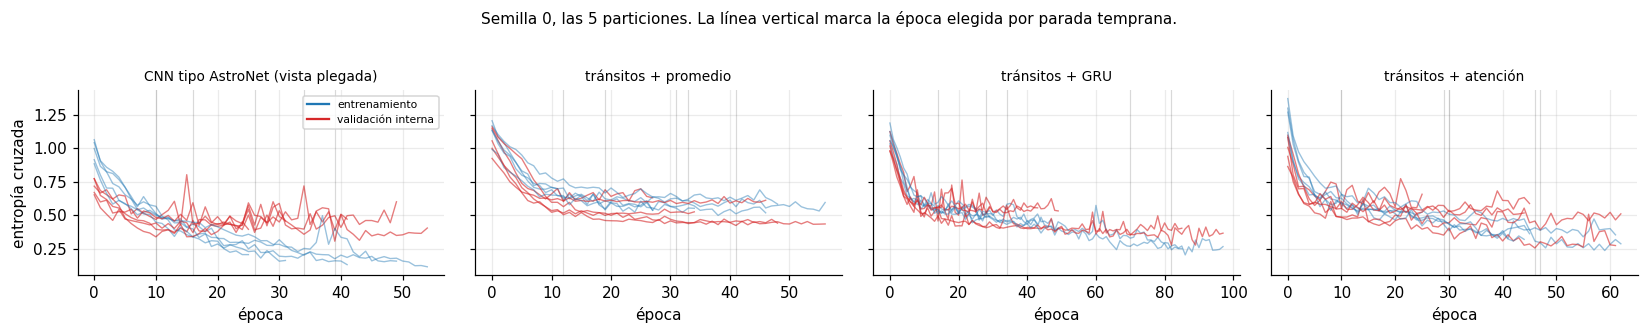

(Vista fija con Semilla: 0. Ejecuta el notebook para usar los controles.)


In [8]:
controles(
    lambda semilla: secciones.curvas_de_perdida(res, semilla),
    semilla=Lista("Semilla:", [0, 1, 2]),
)

## 4 · ¿A qué tránsitos presta atención el modelo?

Doce ejemplos elegidos **al azar con semilla fija** (4 por clase), no por haber acertado. Arriba, los tránsitos uno por uno; abajo, el peso que la atención le dio a cada uno. La línea punteada es el peso que tendría cada tránsito si todos valieran igual (es decir, si la atención se comportara como un promedio).

> Los pesos de atención **describen** qué combinó el modelo; no son una explicación causal de su decisión (Jain y Wallace, 2019).

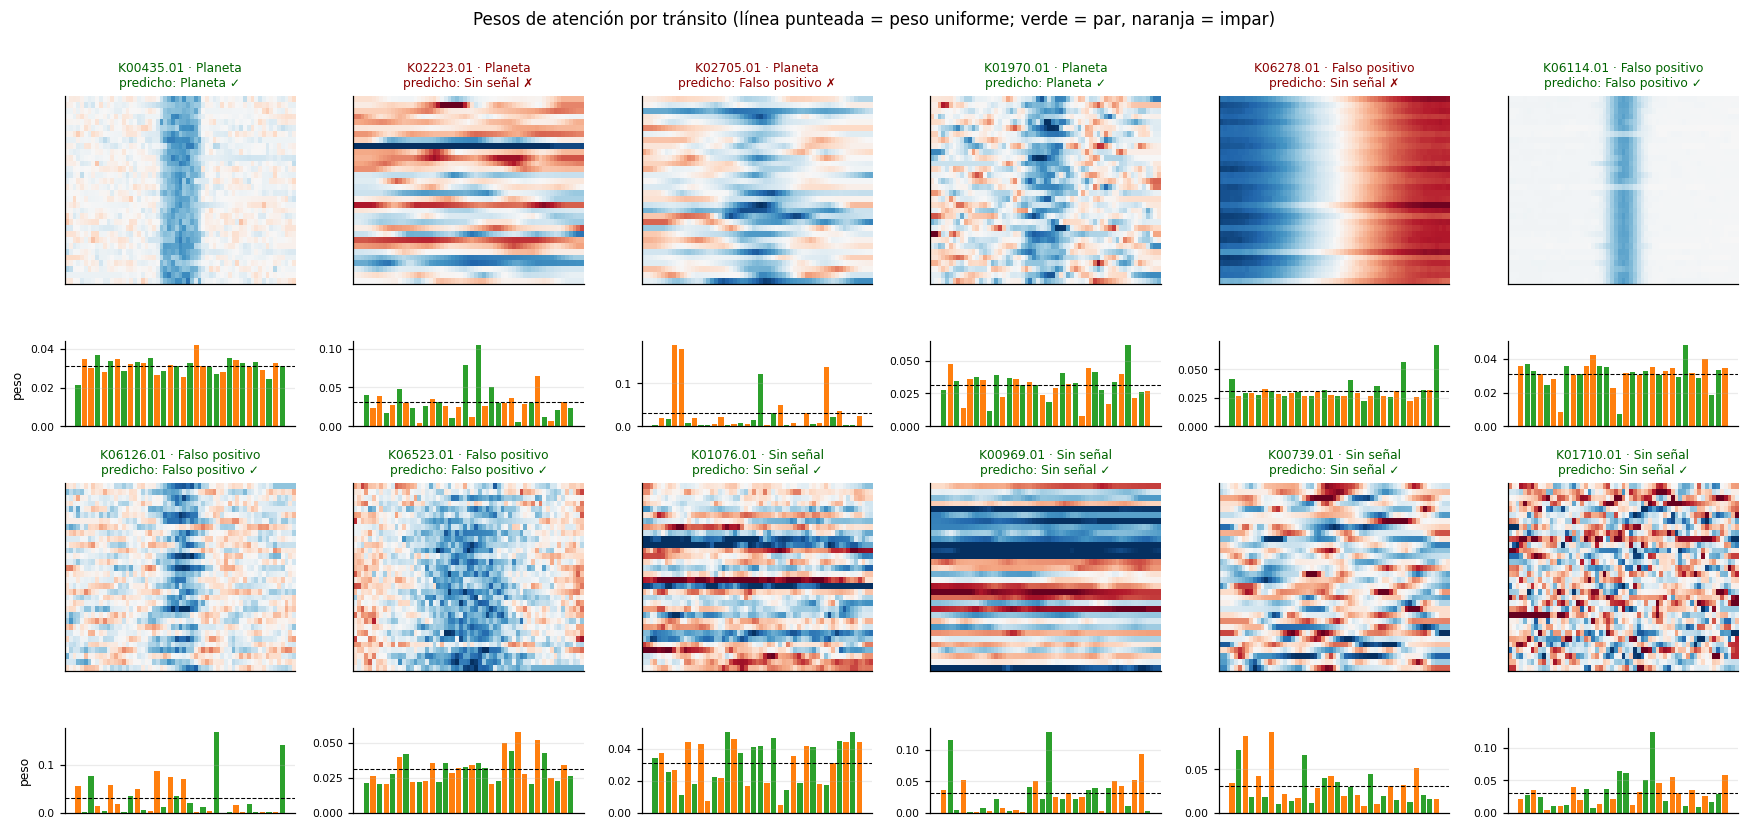

In [9]:
secciones.pesos_de_atencion(res)

## 5 · P2 — ¿Cuánto mejora la decisión al fusionar las cuatro ramas?

Cada rama resume su entrada en un vector (32, 32, 32 y 16 números). La **fusión** concatena los cuatro, agrega 4 banderas de disponibilidad y decide con una capa densa pequeña. Los codificadores están **congelados**, uno por partición, de modo que ninguno vio las estrellas de prueba.

La **ablación** reentrena la cabeza quitando una rama a la vez, o dejando una sola.

**Cómo leer la figura.** A la izquierda, cada configuración. A la derecha, **cuánto pierde** el sistema frente a la fusión completa: verde si la pérdida se distingue de cero.

**Prueba esto.** Cambia la métrica a ECE: la fusión tardía (promediar probabilidades) tiene un AUC parecido, pero un error de calibración claramente mayor.

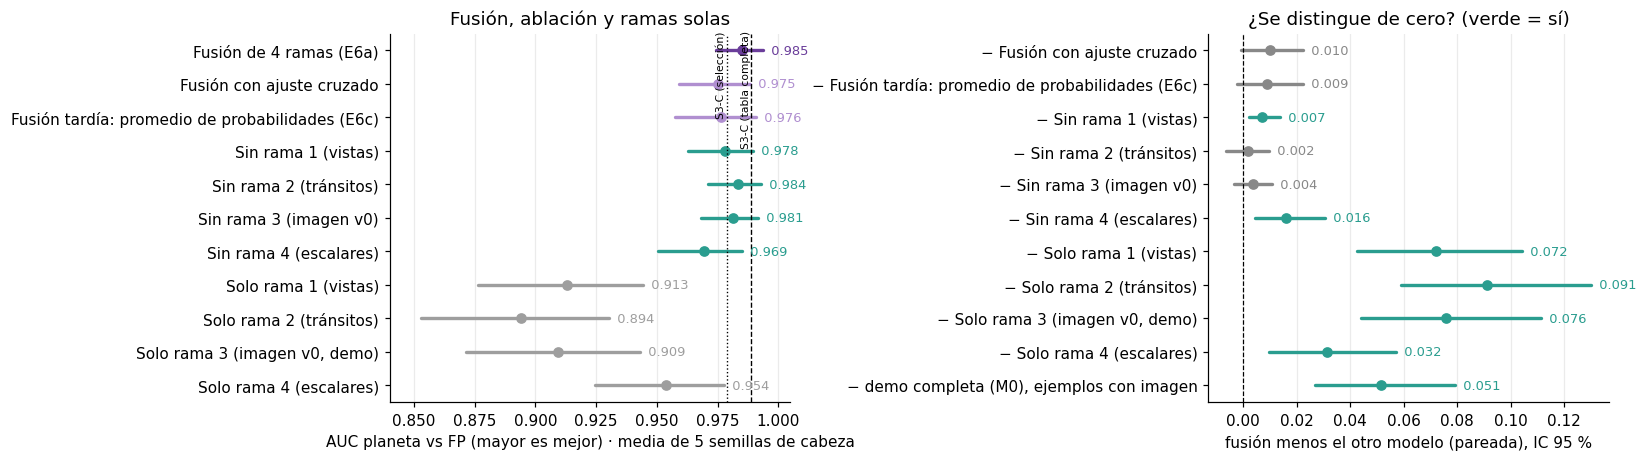

(Vista fija con Métrica: auc_planeta_fp. Ejecuta el notebook para usar los controles.)


In [10]:
controles(
    lambda metrica: secciones.fusion(res, metrica),
    metrica=Lista("Métrica:", METRICAS),
)

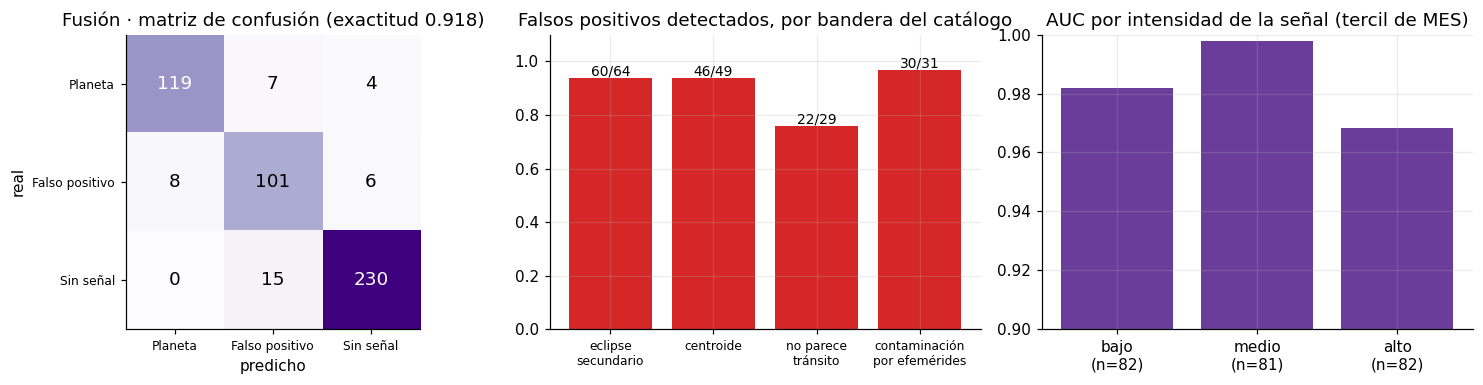

Diagnóstico del apilado: NLL de la cabeza en entrenamiento 0.0497 · en validación interna 0.1786 · razón 3.59 → alerta: True


In [11]:
# La fusión completa por dentro: en qué se equivoca y con qué tipo de señal
secciones.fusion_en_detalle(res)

**Lectura.**

- La **fusión de 4 ramas supera a cualquier rama sola** y a la demo vuelta a medir, con diferencias que se distinguen de cero.
- Al quitar ramas: perder los **escalares** o las **vistas** baja el AUC de forma distinguible. Perder la rama de **tránsitos** o la de **imagen** no se distingue de cero: en este régimen lo que aportan ya lo cubren las otras.
- Frente al listón tabular **S3-C**, la fusión queda **en el mismo rango** (los intervalos se solapan). No se puede afirmar que lo supere.
- **Sin escalares** (solo las tres ramas que aprenden de curvas e imagen) el sistema llega a ~0,97.
- **Alerta de apilado:** la cabeza ve en entrenamiento vectores de ejemplos que los codificadores ya conocían, y por eso queda demasiado confiada (su pérdida en validación es más de 2 veces la de entrenamiento). El remedio previsto —entrenar la cabeza solo con vectores que los codificadores no vieron— elimina la alerta y da un AUC algo menor, no distinguible. La sección siguiente mide y corrige esa sobreconfianza.

## 6 · P3 — ¿Se puede confiar en las probabilidades?

Un modelo puede acertar mucho y aun así mentir sobre su confianza. El **diagrama de confiabilidad** agrupa las predicciones por la confianza declarada y mide cuántas acertó. Si está calibrado, los puntos caen sobre la diagonal; por debajo de ella, el modelo está **sobreconfiado**.

**Temperature scaling:** un solo número (la temperatura *T*) suaviza o afila las probabilidades. Se ajusta en la **validación interna** de cada partición, nunca en la prueba.

**Prueba esto.** Cambia el número de intervalos: con pocos ejemplos por grupo el diagrama se vuelve ruidoso, y por eso el veredicto se apoya en el intervalo de la derecha y no en el dibujo.

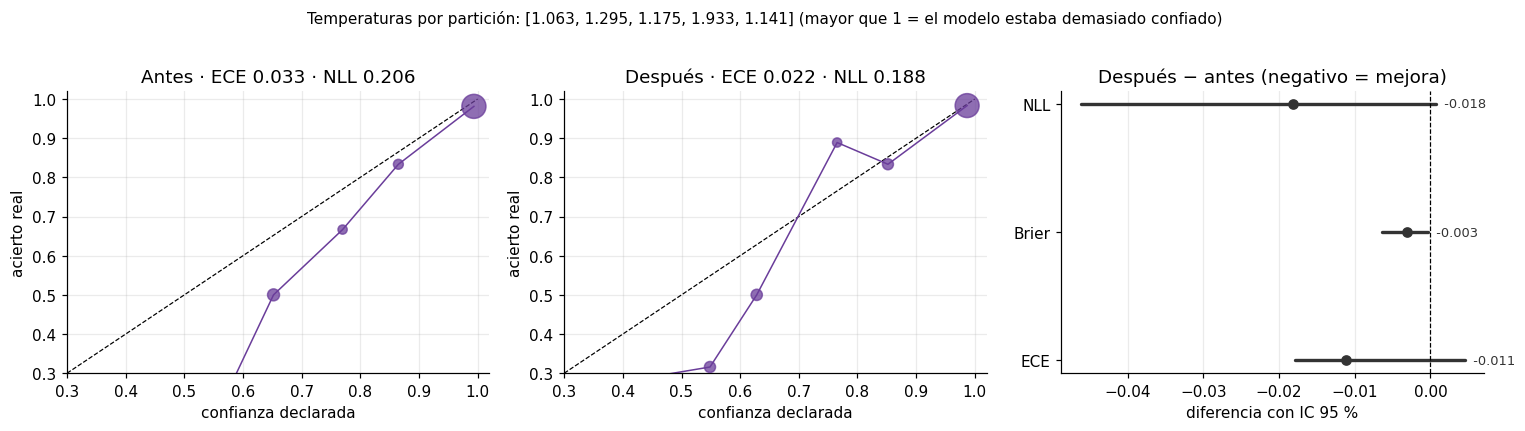

(Vista fija con Intervalos del diagrama: 10. Ejecuta el notebook para usar los controles.)


In [12]:
controles(
    lambda n_intervalos: secciones.calibracion(res, n_intervalos),
    n_intervalos=Deslizador("Intervalos del diagrama:", 5, 20, 1, 10),
)

**Lectura.** Todas las temperaturas son mayores que 1: el sistema estaba **sobreconfiado**, como anticipaba la alerta de apilado. Calibrar baja el ECE y el NLL, pero con ~490 ejemplos **la mejora no se distingue de cero** (los intervalos tocan el 0). El AUC no cambia, como debe ser.

### Juega con la temperatura

Aquí la temperatura la eliges tú y se aplica a **toda** la prueba. Es solo para ver el mecanismo: `softmax(log p / T)`.

> Esto **no** es el resultado del informe. Elegir *T* mirando la prueba sería hacer trampa; en el informe cada *T* sale de la validación interna.

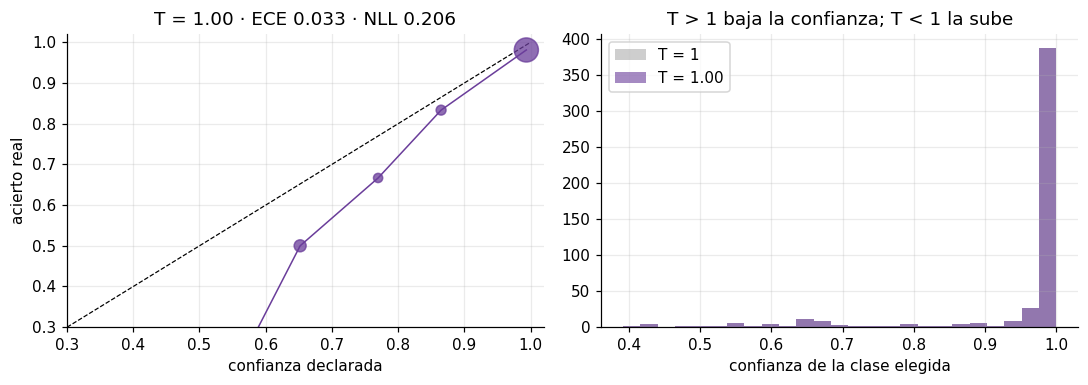

(Vista fija con Temperatura T: 1.0. Ejecuta el notebook para usar los controles.)


In [13]:
controles(
    lambda temperatura: secciones.probar_temperatura(res, temperatura),
    temperatura=Deslizador("Temperatura T:", 0.4, 3.0, 0.1, 1.0),
)

### El prior explícito: ¿y si los planetas fueran escasos?

El modelo se entrenó con casi tantos planetas como falsos positivos. Si en la población real los planetas son raros, sus probabilidades quedan infladas. La corrección de Saerens et al. (2002) reajusta la probabilidad a una **tasa base declarada**. Para evaluarla, la prueba se pondera de modo que emule esa tasa.

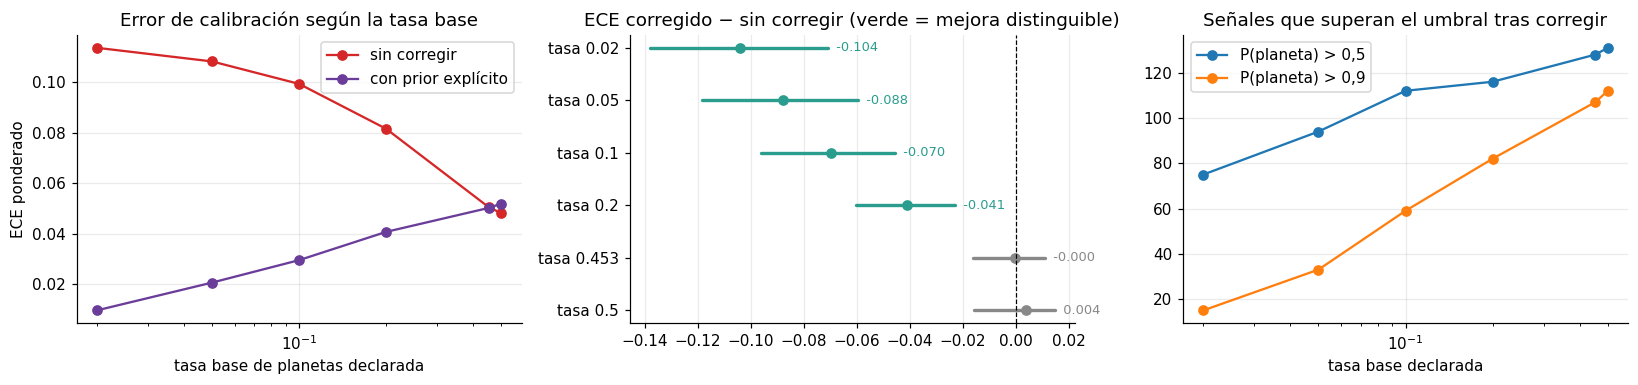

Tasa base medida en DR25 (periodo 1–30 d): {'valor': 0.453, 'confirmados': 2060, 'falsos_positivos': 2487} · tasa de entrenamiento: 0.5306


In [14]:
secciones.prior_explicito(res)

**Lectura.** Cuando la tasa declarada se parece a la de entrenamiento (~0,5) corregir no cambia nada. Cuando los planetas son escasos (tasa ≤ 0,2), **el prior explícito reduce el error de calibración de forma distinguible**, y muchas menos señales superan el umbral. El orden de los candidatos casi no cambia (τ de Kendall > 0,98): la corrección cambia *cuánto* creer, no *a quién* mirar primero.

> **Límite.** La corrección supone que solo cambia la tasa base, no el aspecto de las señales. Eso **no** se cumple entre periodo corto y zona habitable: aquí se demuestra el mecanismo, no su validez en ese régimen.

### Incertidumbre: ¿el modelo duda cuando se equivoca?

Dos formas de medir la duda de la cabeza de fusión: **MC Dropout** (repetir la predicción 50 veces con neuronas apagadas al azar) y un **ensamble** de 5 cabezas entrenadas con semillas distintas.

**Cómo leer la figura.** *Riesgo frente a cobertura*: se ordenan los casos del más seguro al más dudoso y se acepta solo una fracción (la cobertura). Si la duda sirve, al aceptar menos casos el error baja.

**Prueba esto.** Baja la cobertura a 0,90: ¿cuánto cae el error al dejar sin decidir el 10 % más dudoso?

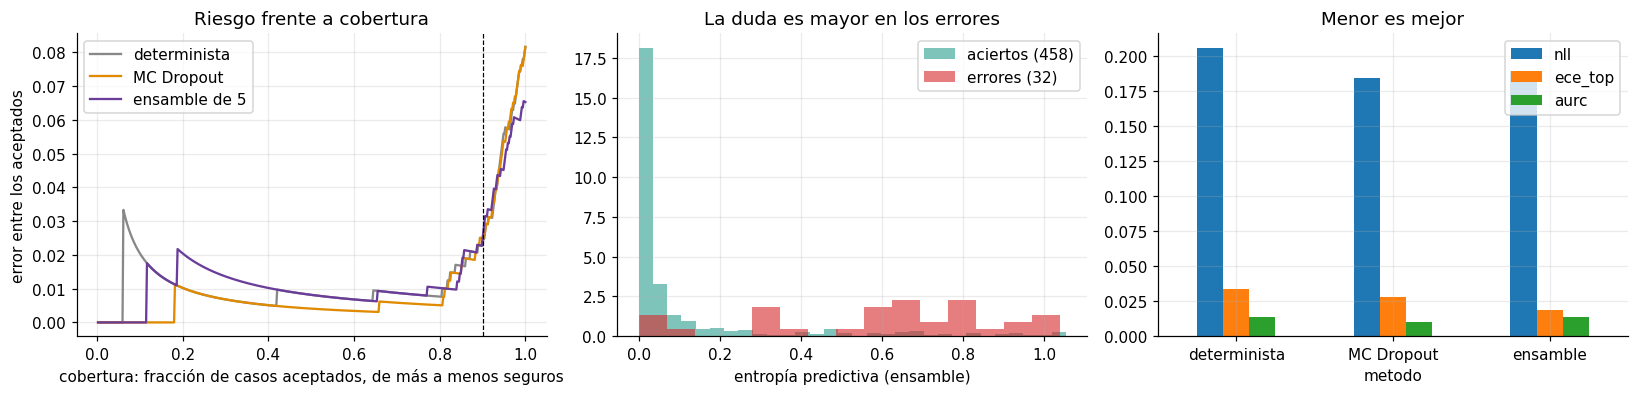

Aceptando el 90% más seguro, el error es → determinista: 2.3% · MC Dropout: 2.5% · ensamble de 5: 2.5%
NLL ensamble − MC Dropout: {'estimacion': 0.0055, 'ic_inf': -0.0164, 'ic_sup': 0.0352}


,nll,brier,ece_top,exactitud,aurc,auroc_deteccion_errores,entropia_media_aciertos,entropia_media_errores,nll_ic_inf,nll_ic_sup
metodo,,,,,,,,,,
determinista_semilla_0,0.2058,0.1034,0.0333,0.9184,0.0140,0.9246,0.0746,0.6270,0.1368,0.2882
mc_dropout,0.1838,0.1014,0.0280,0.9184,0.0103,0.9392,0.1029,0.6692,0.1299,0.2435
ensamble_5_semillas,0.1893,0.0970,0.0190,0.9347,0.0139,0.8886,0.1039,0.6044,0.1273,0.2620


(Vista fija con Cobertura: 0.9. Ejecuta el notebook para usar los controles.)


In [15]:
controles(
    lambda cobertura: secciones.incertidumbre(res, cobertura),
    cobertura=Deslizador("Cobertura:", 0.5, 1.0, 0.05, 0.9),
)

**Lectura.** La incertidumbre **sí avisa**: los errores tienen mucha más entropía que los aciertos, y si se rechaza una pequeña fracción de los casos más dudosos el error cae con fuerza. Entre MC Dropout y el ensamble **no hay una diferencia distinguible** en NLL. La incertidumbre solo cubre la cabeza de fusión, porque los codificadores están congelados.

## 7 · Explorador de señales

Elige cualquier señal y mira **sus datos**, **qué opinó cada rama** y **qué decidió el sistema**.

1. **Grupo:** empieza por *Errores de la fusión* o por *Más dudosos*.
2. **Señal:** cualquiera del grupo.
3. **Tasa base:** mueve el deslizador y mira cómo cambia P(planeta | hay señal) al declarar que los planetas son más escasos.

Debajo de la figura quedan dos líneas con la clase real, la predicha, la duda del sistema y los datos básicos de la señal.

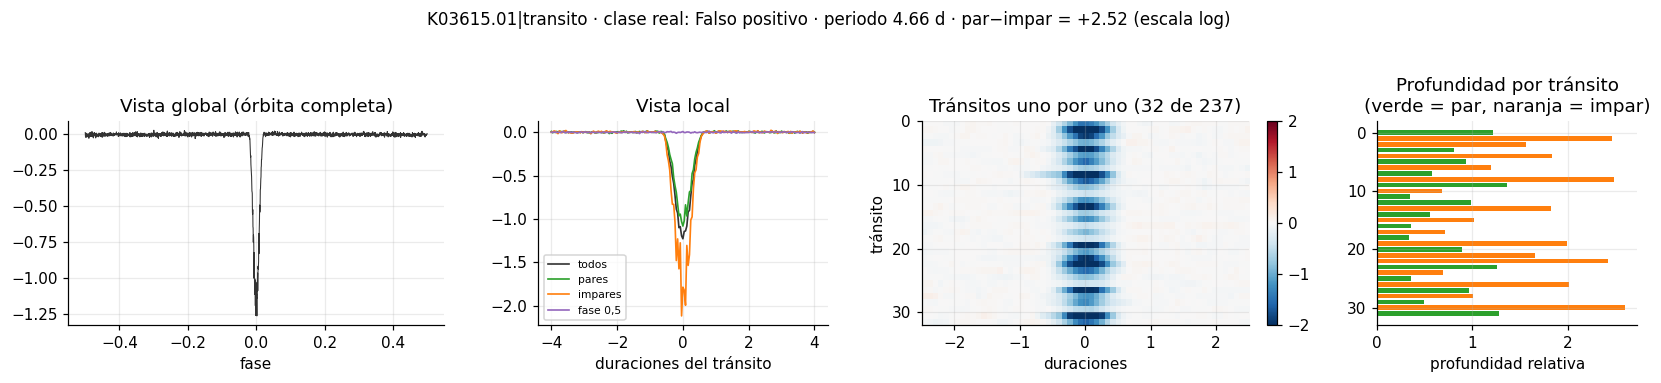

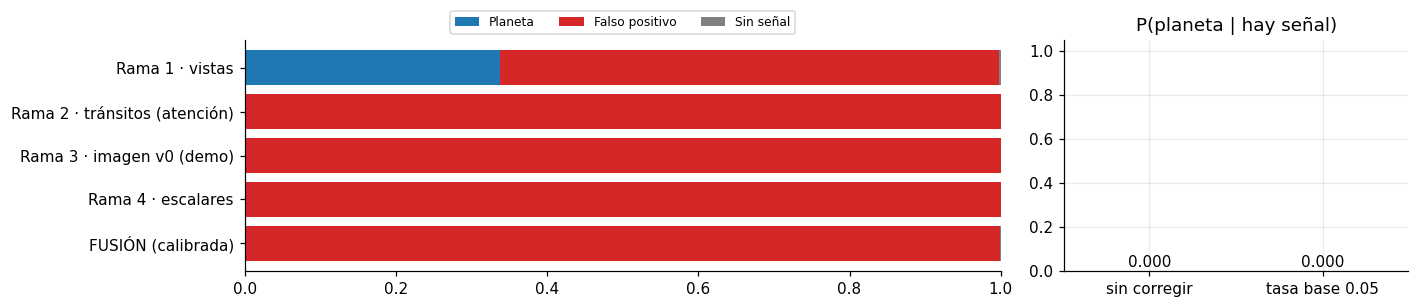

Real: Falso positivo · predicho por la fusión: Falso positivo ✓ · entropía 0.000 · desacuerdo entre cabezas 0.0000
Periodo 4.664 d · duración 3.77 h · profundidad medida 6401 ppm · SNR medido 941.0 · MES 1195.9 · banderas del catálogo (solo informativas, nunca entradas): nt=0 ss=1 co=1 ec=1
(Vista fija. Ejecuta el notebook para elegir cualquier señal.)


In [16]:
explorador = Explorador(res)
explorador.mostrar(caso_fijo="K03615.01|transito", tasa_fija=0.05)

### Dos casos fijos

`K00022.01` es el error típico de la demo: un planeta gigante que su imagen saturaba y clasificaba como falso positivo. El segundo es un error actual del sistema, elegido **al azar con semilla fija** (no a mano). La tabla lista los 10 errores y 10 aciertos sorteados.

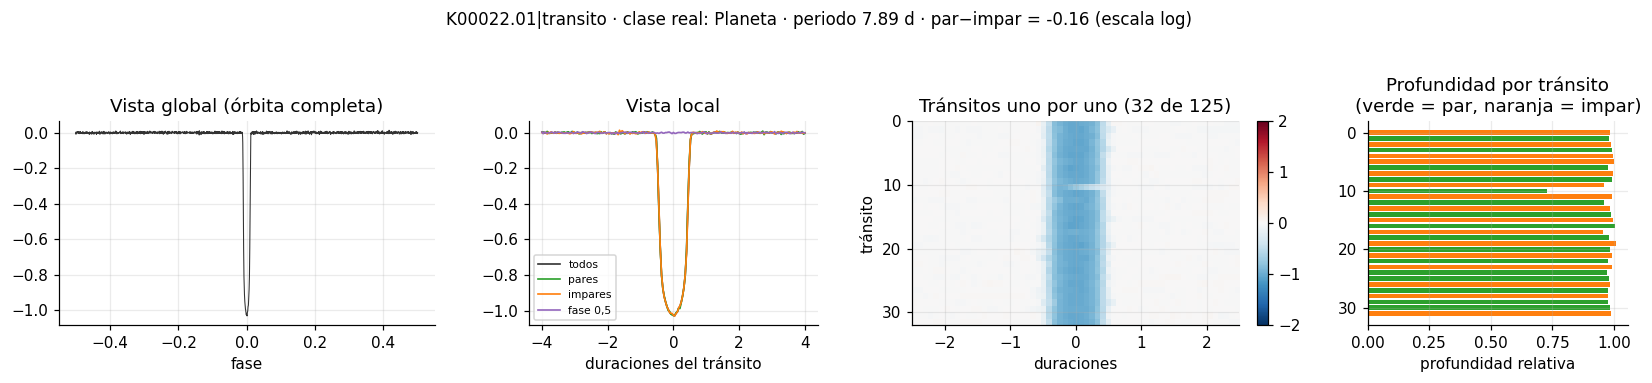

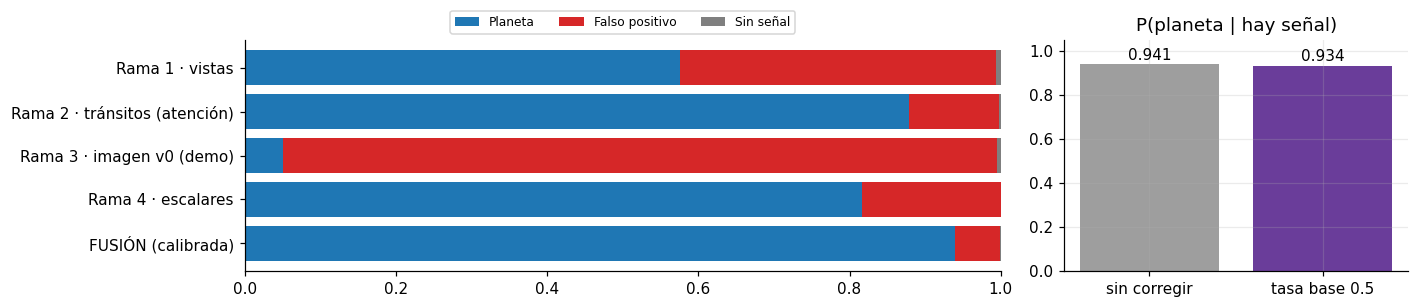

Real: Planeta · predicho por la fusión: Planeta ✓ · entropía 0.196 · desacuerdo entre cabezas 0.0105
Periodo 7.891 d · duración 4.29 h · profundidad medida 10125 ppm · SNR medido 1645.4 · MES 1973.1 · banderas del catálogo (solo informativas, nunca entradas): nt=0 ss=0 co=0 ec=0


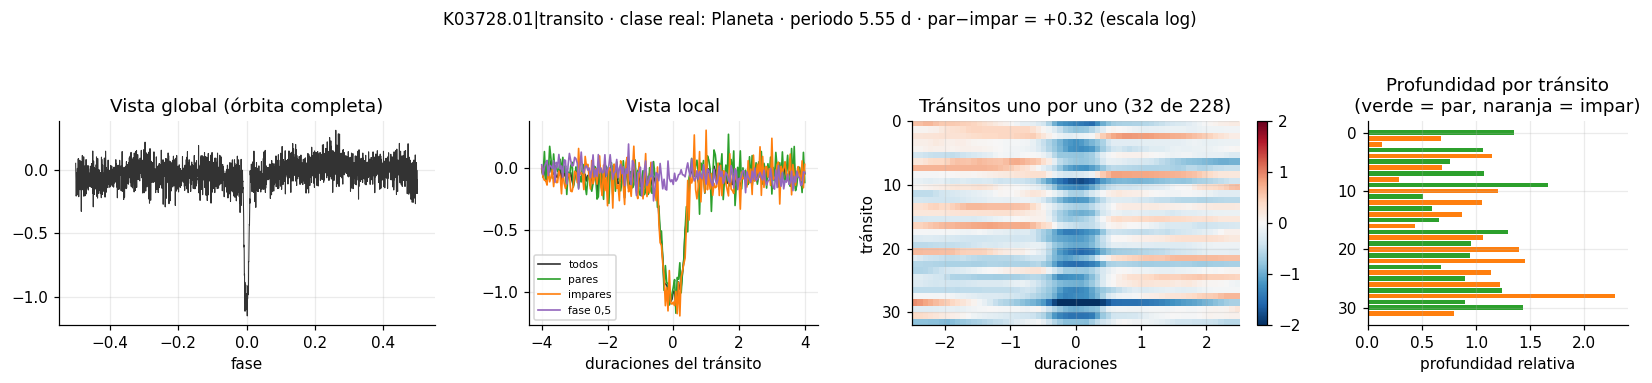

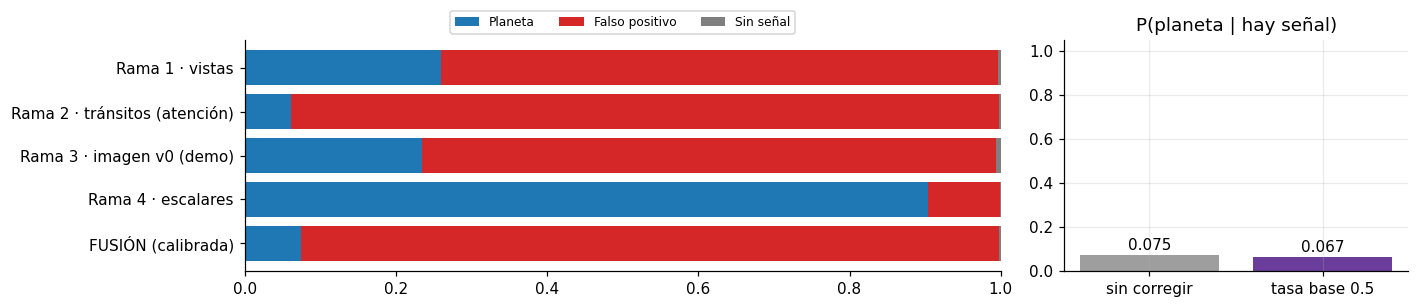

Real: Planeta · predicho por la fusión: Falso positivo ✗ ERROR · entropía 0.282 · desacuerdo entre cabezas 0.0141
Periodo 5.546 d · duración 2.72 h · profundidad medida 2273 ppm · SNR medido 56.7 · MES 154.7 · banderas del catálogo (solo informativas, nunca entradas): nt=0 ss=1 co=0 ec=0


,id_ejemplo,clase_real,prediccion,p_planeta,p_fp,p_sin_senal,entropia,informacion_mutua,seleccion
0,K03728.01|transito,0,1,0.078,0.921,0.001,0.282,0.0141,error al azar
1,K07993.01|sin_senal,2,1,0.180,0.420,0.400,1.039,0.0098,error al azar
2,K00128.01|transito,0,1,0.197,0.803,0.000,0.497,0.0871,error al azar
3,K03216.01|transito,1,2,0.454,0.063,0.483,0.884,0.0984,error al azar
4,K06228.01|transito,0,1,0.165,0.448,0.388,1.024,0.1533,error al azar
5,K00191.01|transito,0,1,0.302,0.697,0.000,0.615,0.0830,error al azar
6,K00081.01|transito,1,0,0.897,0.102,0.000,0.334,0.0120,error al azar
7,K04929.01|transito,1,0,0.683,0.311,0.006,0.655,0.0790,error al azar
8,K05100.01|sin_senal,2,1,0.180,0.420,0.400,1.039,0.0098,error al azar
9,K00897.01|transito,0,1,0.473,0.526,0.001,0.696,0.0072,error al azar


In [17]:
import pandas as pd

casos = pd.read_csv(res.carpeta / "incertidumbre" / "casos_e11.csv")
primer_error = casos[casos.seleccion == "error al azar"].id_ejemplo.iloc[0]

explorador.ver("K00022.01|transito", tasa=0.5)
explorador.ver(primer_error, tasa=0.5)
display(casos)

## 8 · Veredicto de las hipótesis

El veredicto es **mecánico**: una hipótesis "se sostiene" solo si el intervalo del 95 % de la diferencia excluye el 0 en el sentido previsto. Se fijó así antes de ver los resultados.

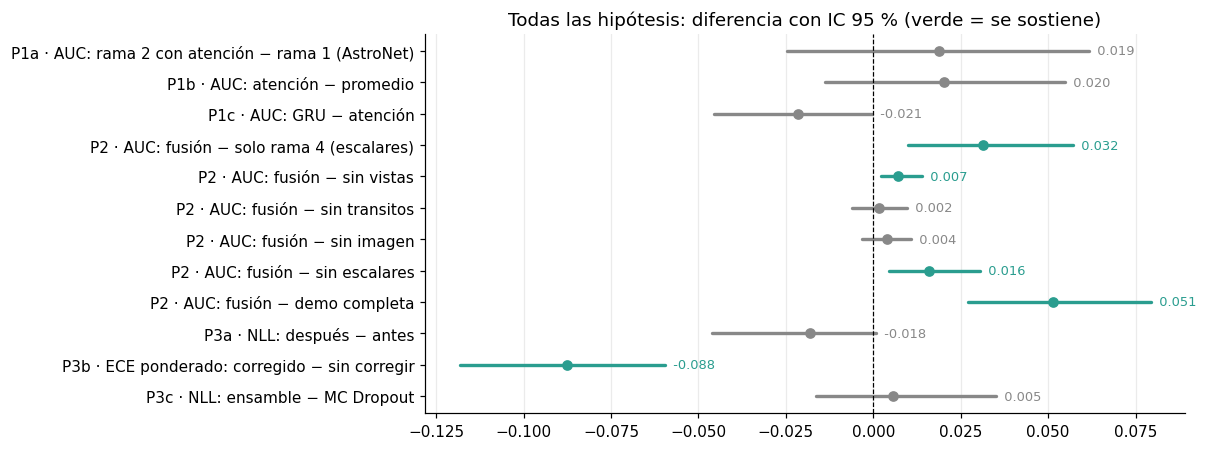

,,hipotesis,pregunta,cantidad,estimacion,ic_inf,ic_sup,veredicto
0,·,P1a,¿La lectura tránsito por tránsito supera a la ...,AUC: rama 2 con atención − rama 1 (AstroNet),0.0189,-0.0247,0.0618,no se sostiene (el intervalo incluye el 0 o va...
1,·,P1b,¿La atención aporta frente al promedio?,AUC: atención − promedio,0.0202,-0.0138,0.0547,no se sostiene (el intervalo incluye el 0 o va...
2,·,P1c,¿La GRU supera a la atención?,AUC: GRU − atención,-0.0215,-0.0456,-0.0004,no se sostiene (el intervalo incluye el 0 o va...
3,✔,P2,¿La fusión supera a la mejor rama sola?,AUC: fusión − solo rama 4 (escalares),0.0315,0.0099,0.0570,se sostiene
4,✔,P2,¿Aporta la rama? (Sin rama 1 (vistas)),AUC: fusión − sin vistas,0.0072,0.0021,0.0138,se sostiene
5,·,P2,¿Aporta la rama? (Sin rama 2 (tránsitos)),AUC: fusión − sin transitos,0.0017,-0.0062,0.0096,no se sostiene (el intervalo incluye el 0 o va...
6,·,P2,¿Aporta la rama? (Sin rama 3 (imagen v0)),AUC: fusión − sin imagen,0.0038,-0.0033,0.0109,no se sostiene (el intervalo incluye el 0 o va...
7,✔,P2,¿Aporta la rama? (Sin rama 4 (escalares)),AUC: fusión − sin escalares,0.0160,0.0046,0.0306,se sostiene
8,✔,P2,¿La fusión supera a la demo vuelta a medir?,AUC: fusión − demo completa,0.0515,0.0270,0.0793,se sostiene
9,·,P3a,¿Mejora el NLL con temperature scaling?,NLL: después − antes,-0.0181,-0.0462,0.0008,no se sostiene (el intervalo incluye el 0 o va...


In [18]:
tabla_hipotesis = secciones.hipotesis(res)
display(tabla_hipotesis)

### En una frase por pregunta

1. **Arquitectura.** La atención entre tránsitos fue la mejor rama temporal en promedio, pero su ventaja sobre el promedio simple y sobre la CNN de curva plegada **no se distingue de cero** en periodo corto. Solo supera de forma distinguible a la GRU.
2. **Fusión.** Unir las cuatro ramas **sí mejora** frente a cualquier rama sola y frente a la demo; queda **al nivel** del mejor modelo tabular con centroide, sin superarlo de forma demostrable.
3. **Calibración.** El sistema salió algo sobreconfiado; la temperatura lo corrige en la dirección esperada sin que la mejora sea distinguible. El **prior explícito sí funciona** de forma distinguible cuando la tasa base es baja. La incertidumbre **señala los errores**; MC Dropout y ensamble empatan.

### Limitaciones que hay que declarar

- **Periodo corto (1–30 días)**, con decenas o cientos de tránsitos: nada de esto permite concluir sobre el régimen de zona habitable.
- **245 señales**: los intervalos son anchos y varias diferencias reales pueden quedar ocultas.
- **Solo señales reales**, sin inyecciones ni falsas alarmas reconstruidas.
- La clase *sin señal* es construida; en ella el centroide siempre falta, lo que le da una pista fácil a la rama 4 (no afecta al AUC planeta vs FP).
- **Circularidad parcial**: parte de las etiquetas de falso positivo se asignaron con el centroide, que también es una entrada.
- **Apilado**: la cabeza de fusión quedó sobreconfiada; se midió y se corrigió con calibración.
- La **rama de imagen es la v0 de la demo** (224 de 245 estrellas tienen imagen); no es un aporte de este curso.
- La incertidumbre solo cubre la cabeza de fusión.
- 23 ejemplos no están disponibles en las ramas temporales (7 estrellas con menos de 4 trimestres y 9 ejemplos *sin señal* de binarias de duración muy larga).